In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, ShuffleSplit, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [3]:
df = pd.read_csv("D:\\Data science\\codes\\files\\breast-cancer-wisconsin-data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


### EDA

### Data cleaning

### Data Transformation


In [4]:
Y = df["diagnosis"]
X = df.iloc[:,2:]

In [5]:
MM = MinMaxScaler()
MM_X = MM.fit_transform(X)
MM_X = pd.DataFrame(MM_X)

### Partationing

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(MM_X,Y, test_size=0.3)

### Model Fit
KNN

In [7]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train,Y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [8]:
Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

### Metrics cal

In [9]:
training_score = accuracy_score(Y_train,Y_pred_train)
print("Training accuracy:",np.round(training_score,3))

test_score = accuracy_score(Y_test, Y_pred_test)
print("Test score:",np.round(test_score,3))

Training accuracy: 0.98
Test score: 0.953


### Cross-Validate
shuffle split

In [10]:
SS = ShuffleSplit(n_splits=100, test_size=0.3)
cv_results = cross_validate(model,MM_X,Y,cv=SS, scoring="accuracy", return_train_score=True)

In [11]:
training_score = cv_results['train_score']
test_score = cv_results['test_score']
print("Training accuracy:",np.round(training_score.mean(),2))
print("Test score:",np.round(test_score.mean(),2))

Training accuracy: 0.98
Test score: 0.97


lets pass different k values

In [12]:
# this is also shuffle split but using for loop
k_training_score = []
k_test_score = []

for i in range(5,21,2):
    model = KNeighborsClassifier(n_neighbors= i)
    SS = ShuffleSplit(n_splits=100, test_size=0.3)
    cv_results = cross_validate(model,MM_X,Y,cv=SS, scoring="accuracy", return_train_score=True)
    train_score = cv_results['train_score']
    test_score = cv_results['test_score']
    k_training_score.append(np.round(train_score.mean(),2))
    k_test_score.append(np.round(test_score.mean(),2))

In [13]:
k_training_score

[0.98, 0.98, 0.98, 0.97, 0.97, 0.97, 0.97, 0.97]

In [14]:
k_test_score

[0.97, 0.97, 0.97, 0.97, 0.97, 0.96, 0.96, 0.96]

### scatter plot

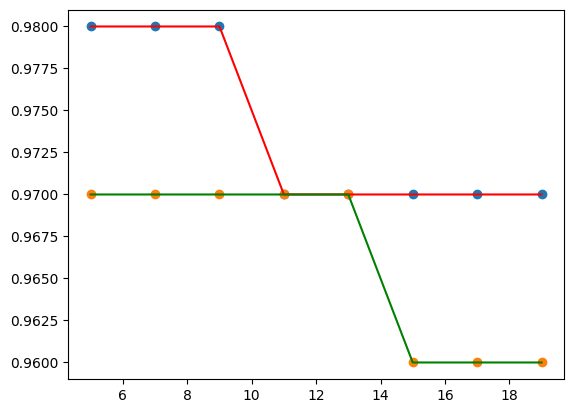

In [15]:
plt.scatter(range(5,21,2),k_training_score)
plt.plot(range(5,21,2),k_training_score,color='red')

plt.scatter(range(5,21,2),k_test_score)
plt.plot(range(5,21,2),k_test_score,color='green')
plt.show()